# Puntos descartados por `pocos_pixeles_buenos`: ejemplos por causa

Dos puntos de cada causa (la ventana 5x5 tiene menos de 5 pixeles buenos). Las imagenes salen del L2R (`rhot`, antes del enmascarado), recortadas alrededor del punto.

- **nube**: algun pixel de la ventana con `CIRRUS` o `MUY_BRILLANTE`
- **borde**: `FUERA_ESCENA` en la ventana, sin nubes
- **no_agua**: solo `NO_AGUA` (`rhos_1600` > 0.05), sin nubes ni borde

Paneles: color natural con la ventana 5x5 en rojo | `l2_flags` por bit | `rhot_1614` (la banda del umbral de `NO_AGUA`).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))

from viz.acolite import visualizar_ventana

import numpy as np
import pandas as pd

from core.ac_tools import dist_punto_pixeles, open_l2w
from core.s3 import DEFAULT_BUCKET, get_s3_client
from tools.ac.extract_windows import ACOLITE_SAVE_DIR, half
from dotenv import load_dotenv
import xarray as xr

load_dotenv(ROOT / ".env")
ACOLITE_SAVE_DIR = ROOT / ACOLITE_SAVE_DIR

df = pd.read_csv(ROOT / "data/nuevos/matchups_ventanas.csv", index_col="matchup_index")

# matchup_index de cada ejemplo
ejemplos = {
    "nube": [8, 21],
    "borde": [51, 242],
    "no_agua": [129, 263],
}


In [2]:
def l2r_de(l2w_path, s3, bucket=DEFAULT_BUCKET):
    # el L2R esta junto al L2W en s3; se baja si no esta
    l2r = l2w_path.with_name(l2w_path.name.replace("L2W", "L2R"))
    if not l2r.exists():
        parte = l2w_path.parent.name if l2w_path.parent.name.startswith("parte") else None
        pass_id = l2w_path.parent.parent.name if parte else l2w_path.parent.name
        key = "/".join(["acolite", pass_id] + ([parte] if parte else []) + [l2r.name])
        s3.download_file(bucket, key, str(l2r))
    return xr.open_dataset(l2r).load()


def buscar(p, pass_id):
    # parte (L2W) con el pixel mas cercano al punto
    mejor = None
    for path in sorted((ACOLITE_SAVE_DIR / pass_id).glob("**/*L2W.nc")):
        dl = open_l2w(path)
        d2 = dist_punto_pixeles(p, dl["lat"].values, dl["lon"].values)
        i, j = np.unravel_index(np.nanargmin(d2), d2.shape)
        if mejor is None or d2[i, j] < mejor[0]:
            mejor = (d2[i, j], i, j, path, dl)
    return mejor[1:]

[nube] matchup 8  S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_20230923T131421  grupo LDS
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25, 'MUY_BRILLANTE': 1}   buenos: 0


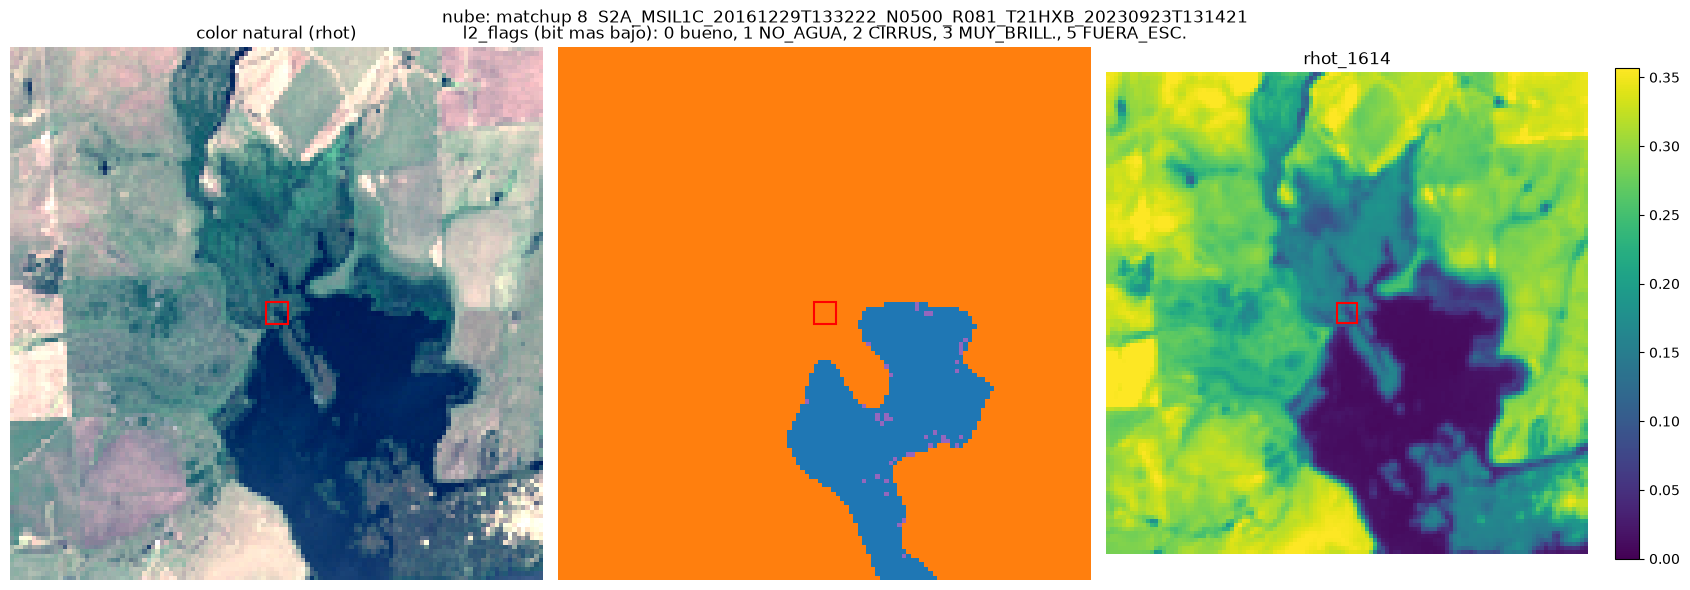

[nube] matchup 21  S2A_MSIL1C_20170111T134141_N0500_R124_T21HXB_20231014T070720  grupo LDS
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25, 'MUY_BRILLANTE': 25}   buenos: 0


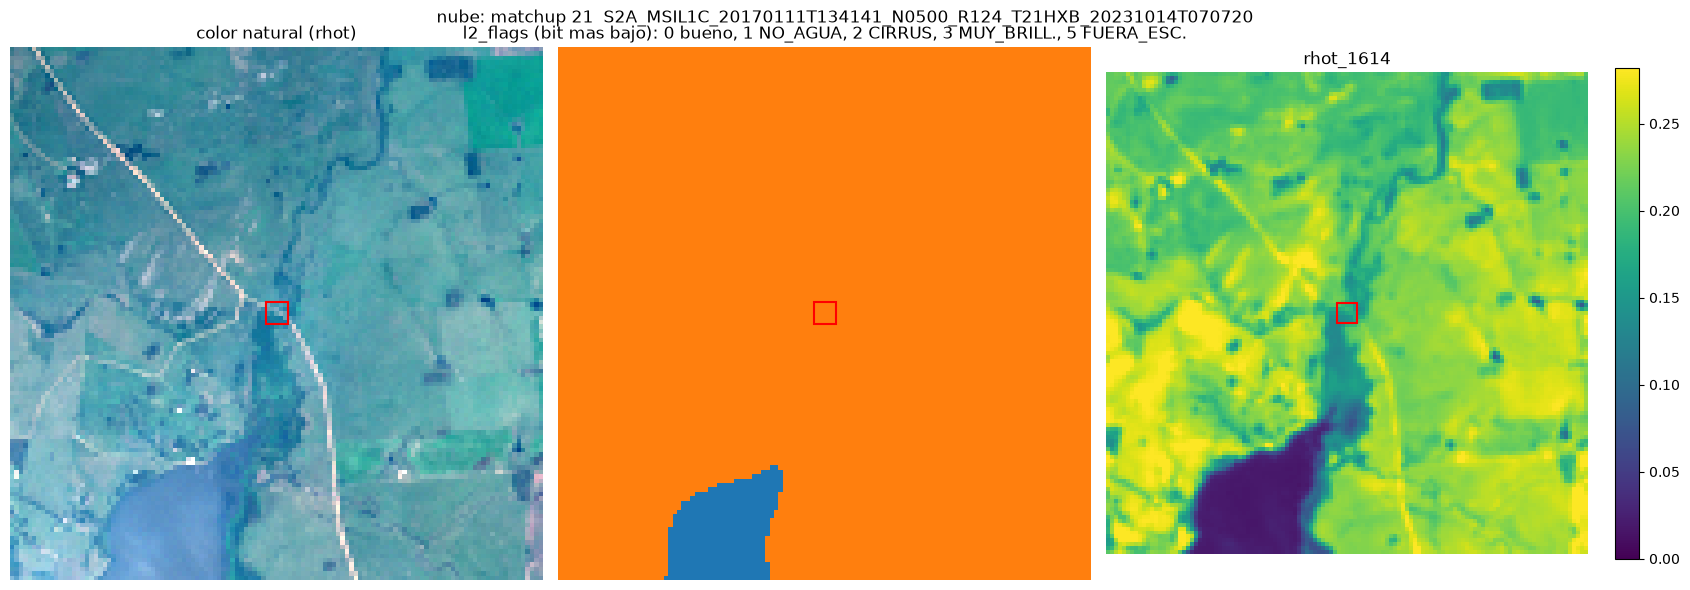

[borde] matchup 51  S2A_MSIL1C_20170203T140151_N0500_R024_T21HUC_20231015T015326  grupo RDP-MONTES
   flags en la ventana (pixeles de 25): {'FUERA_ESCENA': 25}   buenos: 0


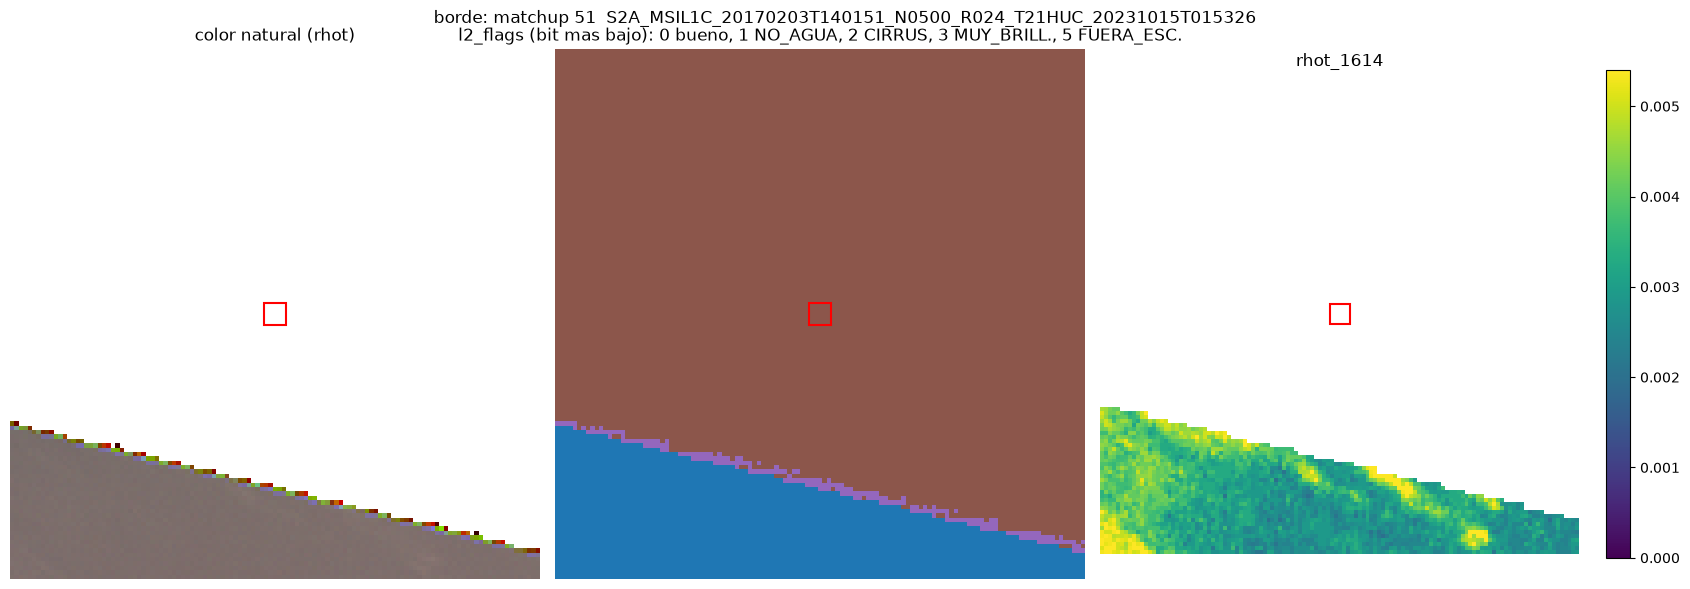

[borde] matchup 242  S2A_MSIL1C_20171031T140201_N0500_R024_T21HUC_20230721T144601  grupo RDP-MONTES
   flags en la ventana (pixeles de 25): {'FUERA_ESCENA': 25}   buenos: 0


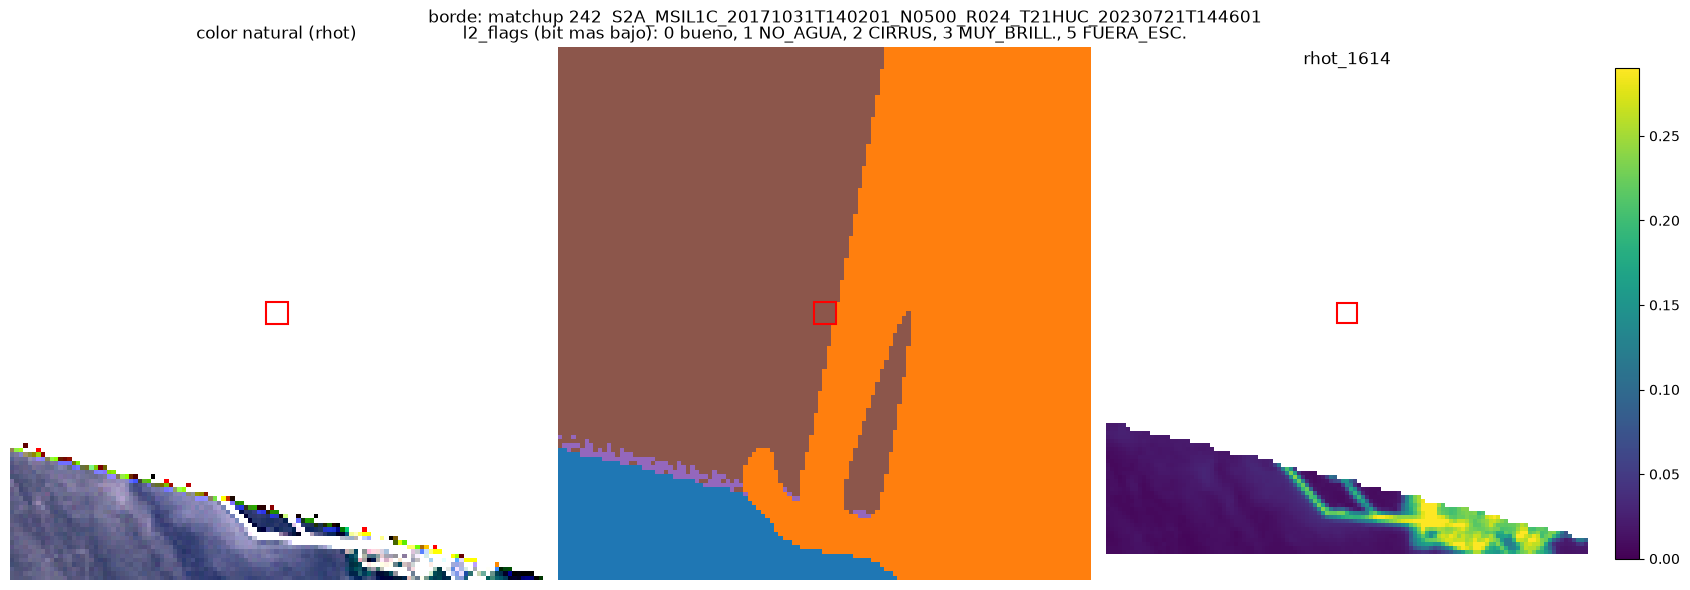

[no_agua] matchup 129  S2A_MSIL1C_20170404T135111_N0500_R024_T21HUC_20230925T141242  grupo RDP-MONTES
   flags en la ventana (pixeles de 25): {'NO_AGUA': 21}   buenos: 4


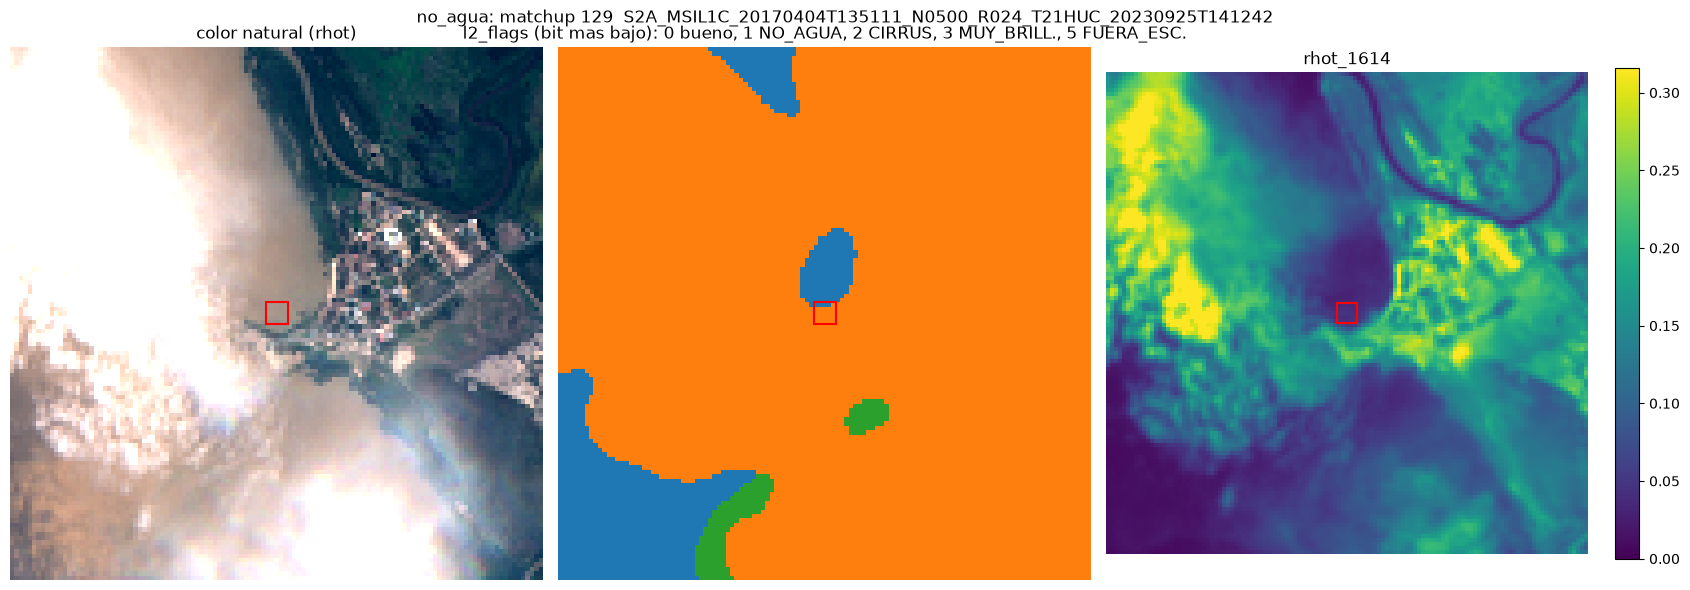

[no_agua] matchup 263  S2A_MSIL1C_20171210T140151_N0500_R024_T21HUC_20230718T201816  grupo RDP-MONTES
   flags en la ventana (pixeles de 25): {'NO_AGUA': 25}   buenos: 0


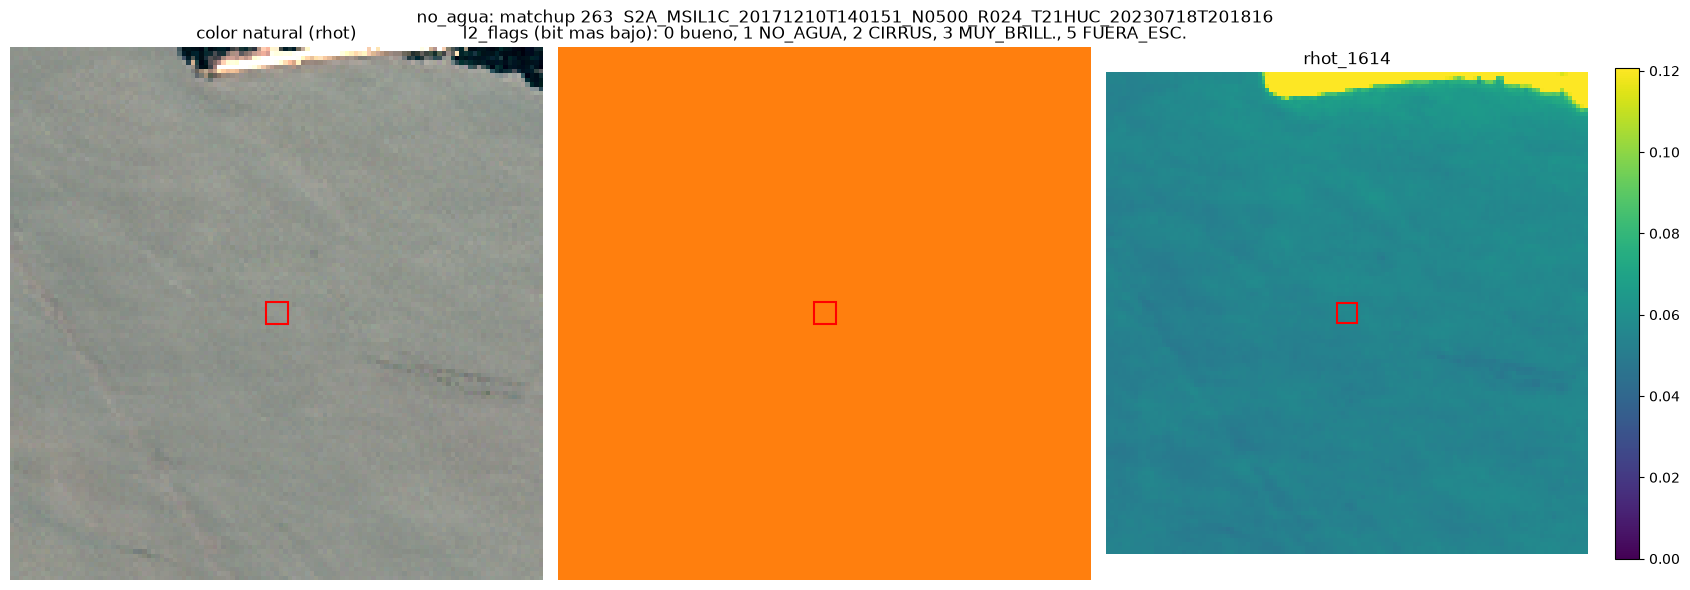

In [3]:
s3 = get_s3_client()
R = 60  # recorte: +-R pixeles alrededor del punto

for causa, idxs in ejemplos.items():
    for idx in idxs:
        p = df.loc[idx]
        i, j, path, w = buscar(p, p["pass_id"])
        r = l2r_de(path, s3)

        visualizar_ventana(
            r, w, i, j, causa=causa, idx=idx, pass_id=p["pass_id"],
            grupo_nombre=p["grupo_nombre"], radio=R, half=half,
            longitud_onda=1614, percentil=98,
        )
